# Hands-On Data Lab Implementation
**Task 2 – Yuva Intern | Data Science**

This notebook builds a working data-analysis environment and completes practical exercises on a retail sales dataset:
1. Environment setup check
2. Data selection, filtering, sorting, grouping, aggregation and merging with Pandas & NumPy
3. Data cleaning
4. Data visualization with Matplotlib & Seaborn
5. Descriptive statistics and relationship analysis
6. Observations and insights

> The dataset is generated in code with a fixed random seed (`42`), so every run gives identical results. It is deliberately created with real-world problems (missing values, duplicates, inconsistent text, wrong data types, outliers) so the cleaning steps are meaningful.

## 1. Set Up the Data Science Environment

In [1]:
import sys, platform
import numpy as np, pandas as pd, matplotlib, seaborn as sns, sklearn
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0], "|", platform.system())
for name, lib in [("NumPy", np), ("Pandas", pd), ("Matplotlib", matplotlib), ("Seaborn", sns), ("Scikit-learn", sklearn)]:
    print(f"{name:<12}:", lib.__version__)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

Python      : 3.12.3 | Linux
NumPy       : 2.4.4
Pandas      : 3.0.2
Matplotlib  : 3.10.8
Seaborn     : 0.13.2
Scikit-learn: 1.8.0


To recreate this environment:
```bash
python -m venv venv
venv\Scripts\activate          # Windows  (Linux/Mac: source venv/bin/activate)
pip install -r requirements.txt
jupyter notebook
```

## 2. Create / Load the Dataset (NumPy)

In [2]:
rng = np.random.default_rng(42)
n = 600

cities    = ["Palakkad", "Kochi", "Coimbatore", "Chennai", "Bengaluru"]
products  = {"Laptop": 55000, "Smartphone": 18000, "Headphones": 2500, "Smartwatch": 6000, "Tablet": 22000, "Keyboard": 900}
channels  = ["Online", "Store"]

df = pd.DataFrame({
    "order_id":   np.arange(1001, 1001 + n),
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "city":       rng.choice(cities, n, p=[0.15, 0.30, 0.20, 0.20, 0.15]),
    "product":    rng.choice(list(products), n, p=[0.10, 0.25, 0.20, 0.15, 0.10, 0.20]),
    "channel":    rng.choice(channels, n, p=[0.6, 0.4]),
    "quantity":   rng.integers(1, 6, n).astype(float),
    "discount_pct": rng.choice([0, 5, 10, 15, 20], n, p=[0.35, 0.25, 0.2, 0.1, 0.1]).astype(float),
    "customer_age": rng.normal(32, 9, n).round().clip(18, 65),
})
base = df["product"].map(products)
df["unit_price"] = (base * rng.normal(1, 0.05, n)).round(0)
df["rating"] = np.clip(rng.normal(4.0, 0.7, n) - df["discount_pct"] * 0.01, 1, 5).round(1)

# ---- inject realistic data-quality problems ----
raw = df.copy()
raw.loc[rng.choice(n, 30, replace=False), "quantity"] = np.nan                 # missing values
raw.loc[rng.choice(n, 25, replace=False), "customer_age"] = np.nan
raw.loc[rng.choice(n, 20, replace=False), "rating"] = np.nan
raw.loc[rng.choice(n, 15, replace=False), "city"] = None
raw["city"] = raw["city"].apply(lambda x: x if pd.isna(x) or rng.random() > 0.15 else rng.choice([x.lower(), x.upper(), " " + x + " "]))  # inconsistent text
raw["product"] = raw["product"].apply(lambda x: x if rng.random() > 0.1 else x.lower())
raw["unit_price"] = raw["unit_price"].apply(lambda v: f"Rs.{int(v):,}")           # wrong dtype (text)
raw.loc[rng.choice(n, 5, replace=False), "customer_age"] = 250                     # impossible ages
raw = pd.concat([raw, raw.sample(20, random_state=1)], ignore_index=True)          # duplicate rows

raw.to_csv("data/sales_raw.csv", index=False)
raw.head()

,order_id,order_date,city,product,channel,quantity,discount_pct,customer_age,unit_price,rating
0,1001,2025-02-02,Chennai,Headphones,Store,4.0,5.0,42.0,"Rs.2,544",3.9
1,1002,2025-10-10,Palakkad,Smartphone,Store,4.0,10.0,25.0,"Rs.18,424",3.2
2,1003,2025-08-27,coimbatore,Laptop,Online,2.0,10.0,18.0,"Rs.51,327",3.5
3,1004,2025-06-10,Coimbatore,Headphones,Online,1.0,15.0,18.0,"Rs.2,617",4.8
4,1005,2025-06-08,Bengaluru,keyboard,Store,2.0,15.0,45.0,Rs.885,4.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 620 entries, 0 to 619
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      620 non-null    int64         
 1   order_date    620 non-null    datetime64[us]
 2   city          604 non-null    str           
 3   product       620 non-null    str           
 4   channel       620 non-null    str           
 5   quantity      590 non-null    float64       
 6   discount_pct  620 non-null    float64       
 7   customer_age  595 non-null    float64       
 8   unit_price    620 non-null    str           
 9   rating        599 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(4)
memory usage: 48.6 KB


## 3. Working with Data Using Pandas & NumPy

### 3.1 Selection

In [4]:
print(raw["product"].head(3).tolist())                    # single column
print(raw[["order_id", "city", "quantity"]].head(3))      # multiple columns
print(raw.iloc[10:13, 0:4])                               # by position
print(raw.loc[raw["order_id"] == 1005, ["product", "city"]])   # by label/condition

['Headphones', 'Smartphone', 'Laptop']
   order_id        city  quantity
0      1001     Chennai       4.0
1      1002    Palakkad       4.0
2      1003  coimbatore       2.0
    order_id order_date        city   product
10      1011 2025-07-12  Coimbatore    Tablet
11      1012 2025-12-23       Kochi  Keyboard
12      1013 2025-09-26       Kochi  Keyboard
    product       city
4  keyboard  Bengaluru


### 3.2 Filtering & Sorting

In [5]:
online_blr = raw[(raw["channel"] == "Online") & (raw["city"] == "Bengaluru")]
print("Online orders in Bengaluru:", len(online_blr))

high_discount = raw[raw["discount_pct"] >= 15]
print("Orders with >=15% discount:", len(high_discount))

raw.sort_values(["order_date", "order_id"], ascending=[False, True]).head(5)

Online orders in Bengaluru: 56
Orders with >=15% discount: 127


,order_id,order_date,city,product,channel,quantity,discount_pct,customer_age,unit_price,rating
400,1401,2025-12-31,Kochi,Smartphone,Online,NaN,20.0,28.0,"Rs.18,989",2.8
160,1161,2025-12-30,Coimbatore,Keyboard,Online,1.0,10.0,25.0,Rs.840,4.8
510,1511,2025-12-30,PALAKKAD,Keyboard,Online,2.0,10.0,29.0,Rs.835,3.9
144,1145,2025-12-29,Kochi,Laptop,Online,2.0,5.0,18.0,"Rs.56,680",3.8
355,1356,2025-12-29,Kochi,Keyboard,Store,2.0,10.0,28.0,Rs.888,4.2


### 3.3 NumPy numerical operations

In [6]:
ages = raw["customer_age"].to_numpy(dtype=float)
valid = ages[(~np.isnan(ages)) & (ages <= 100)]
print("Mean age   :", np.mean(valid).round(2))
print("Median age :", np.median(valid))
print("Std dev    :", np.std(valid).round(2))
print("Percentiles (25/50/75):", np.percentile(valid, [25, 50, 75]))

# vectorised operation – z-scores
z = (valid - valid.mean()) / valid.std()
print("Ages with |z| > 2.5:", (np.abs(z) > 2.5).sum())

Mean age   : 32.5
Median age : 32.0
Std dev    : 8.37
Percentiles (25/50/75): [26.25 32.   38.  ]
Ages with |z| > 2.5: 6


## 4. Data Cleaning

### 4.1 Identify the problems

In [7]:
print("Missing values per column:\n", raw.isna().sum(), "\n")
print("Duplicate rows:", raw.duplicated().sum())
print("City values  :", sorted(raw["city"].dropna().unique()))
print("Product values:", sorted(raw["product"].unique()))
print("unit_price dtype:", raw["unit_price"].dtype, "| example:", raw["unit_price"].iloc[0])
print("Max age:", raw["customer_age"].max())

Missing values per column:
 order_id         0
order_date       0
city            16
product          0
channel          0
quantity        30
discount_pct     0
customer_age    25
unit_price       0
rating          21
dtype: int64 

Duplicate rows: 20
City values  : [np.str_(' Bengaluru '), np.str_(' Chennai '), np.str_(' Coimbatore '), np.str_(' Kochi '), np.str_(' Palakkad '), np.str_('BENGALURU'), 'Bengaluru', np.str_('CHENNAI'), np.str_('COIMBATORE'), 'Chennai', 'Coimbatore', np.str_('KOCHI'), 'Kochi', np.str_('PALAKKAD'), 'Palakkad', np.str_('bengaluru'), np.str_('chennai'), np.str_('coimbatore'), np.str_('kochi'), np.str_('palakkad')]
Product values: ['Headphones', 'Keyboard', 'Laptop', 'Smartphone', 'Smartwatch', 'Tablet', 'headphones', 'keyboard', 'laptop', 'smartphone', 'smartwatch', 'tablet']
unit_price dtype: str | example: Rs.2,544
Max age: 250.0


### 4.2 Fix them

In [8]:
df = raw.copy()

# 1. remove exact duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}")

# 2. fix inconsistent text
df["city"] = df["city"].str.strip().str.title()
df["product"] = df["product"].str.strip().str.title()

# 3. fix data types
df["unit_price"] = df["unit_price"].str.replace(r"[^0-9]", "", regex=True).astype(int)
df["order_date"] = pd.to_datetime(df["order_date"])

# 4. impossible values -> NaN, then impute
df.loc[df["customer_age"] > 100, "customer_age"] = np.nan

# 5. handle missing values
df["city"] = df["city"].fillna("Unknown")
df["quantity"] = df["quantity"].fillna(df["quantity"].median()).astype(int)
df["customer_age"] = df["customer_age"].fillna(df["customer_age"].median()).astype(int)
df["rating"] = df.groupby("product")["rating"].transform(lambda s: s.fillna(s.median()))

# 6. feature engineering
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["age_group"] = pd.cut(df["customer_age"], bins=[17, 25, 35, 45, 70], labels=["18-25", "26-35", "36-45", "46+"])

print("\nRemaining missing values:", int(df.isna().sum().sum()))
df.to_csv("data/sales_clean.csv", index=False)
df.info()

Duplicates removed: 20

Remaining missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      600 non-null    int64         
 1   order_date    600 non-null    datetime64[us]
 2   city          600 non-null    str           
 3   product       600 non-null    str           
 4   channel       600 non-null    str           
 5   quantity      600 non-null    int64         
 6   discount_pct  600 non-null    float64       
 7   customer_age  600 non-null    int64         
 8   unit_price    600 non-null    int64         
 9   rating        600 non-null    float64       
 10  revenue       600 non-null    float64       
 11  month         600 non-null    str           
 12  age_group     600 non-null    category      
dtypes: category(1), datetime64[us](1), float64(3), int64(4), str(4)
memory usage: 57.0 KB


### 4.3 Outlier check (IQR method)

In [9]:
q1, q3 = df["revenue"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outliers = df[df["revenue"] > upper]
print(f"Revenue upper fence: {upper:,.0f} | high-revenue orders: {len(outliers)} ({len(outliers)/len(df):.1%})")
print(outliers["product"].value_counts())

Revenue upper fence: 107,734 | high-revenue orders: 39 (6.5%)
product
Laptop    36
Tablet     3
Name: count, dtype: int64


Large revenue values come almost entirely from high-priced products (Laptop, Tablet) bought in bulk, so they are genuine and are **kept** rather than removed.

## 5. Grouping, Aggregation & Merging

In [10]:
by_product = df.groupby("product").agg(orders=("order_id", "count"),
                                      units=("quantity", "sum"),
                                      revenue=("revenue", "sum"),
                                      avg_rating=("rating", "mean")).round(2).sort_values("revenue", ascending=False)
by_product

,orders,units,revenue,avg_rating
product,,,,
Laptop,56,157,8005896.10,3.98
Smartphone,150,423,6948682.05,3.88
Tablet,48,119,2459569.90,3.88
Smartwatch,82,240,1380088.60,3.98
Headphones,131,383,894598.75,3.92
Keyboard,133,411,344906.70,3.90


In [11]:
by_city_channel = df.pivot_table(index="city", columns="channel", values="revenue", aggfunc="sum").round(0)
by_city_channel

channel,Online,Store
city,,
Bengaluru,1719417.0,761662.0
Chennai,1711068.0,1916599.0
Coimbatore,2070152.0,1424849.0
Kochi,3694216.0,2676011.0
Palakkad,2561219.0,1062995.0
Unknown,89013.0,346542.0


In [12]:
# Merging: add city-level metadata (a second table) to the sales data
city_info = pd.DataFrame({"city": ["Palakkad", "Kochi", "Coimbatore", "Chennai", "Bengaluru", "Unknown"],
                          "state": ["Kerala", "Kerala", "Tamil Nadu", "Tamil Nadu", "Karnataka", "-"],
                          "tier":  ["Tier-3", "Tier-2", "Tier-2", "Tier-1", "Tier-1", "-"]})
merged = df.merge(city_info, on="city", how="left")
print(merged.groupby("tier")["revenue"].agg(["count", "sum", "mean"]).round(0))

        count        sum     mean
tier                             
-          15   435556.0  29037.0
Tier-1    205  6108746.0  29799.0
Tier-2    283  9865228.0  34859.0
Tier-3     97  3624213.0  37363.0


## 6. Data Visualization

In [13]:
import os; os.makedirs("images", exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130); plt.show()

### 6.1 Bar chart – revenue by product

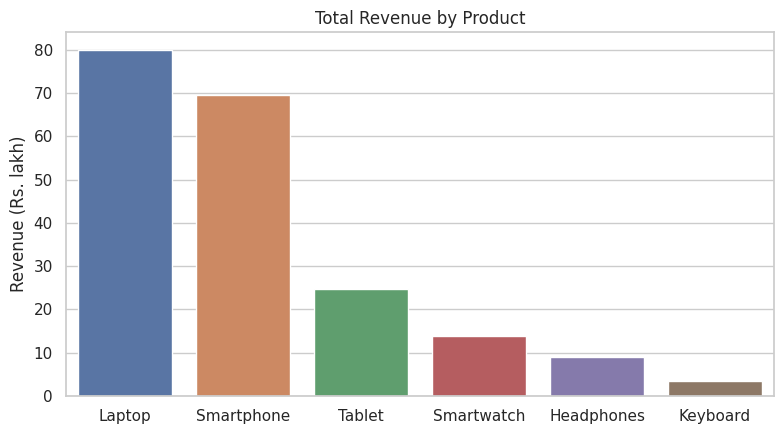

In [14]:
plt.figure(figsize=(8,4.5))
order = by_product.index
sns.barplot(x=by_product.index, y=by_product["revenue"]/1e5, order=order, hue=by_product.index, legend=False)
plt.title("Total Revenue by Product"); plt.ylabel("Revenue (Rs. lakh)"); plt.xlabel("")
save("01_bar_revenue_product")

### 6.2 Line chart – monthly revenue trend

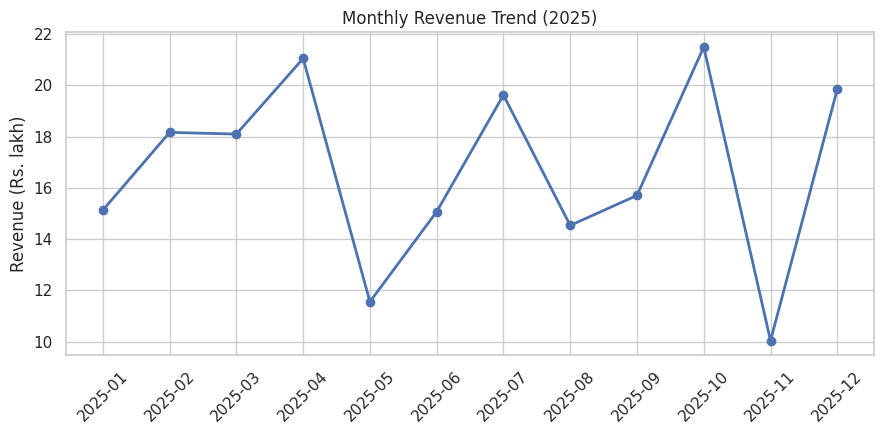

In [15]:
monthly = df.groupby("month")["revenue"].sum() / 1e5
plt.figure(figsize=(9,4.5))
plt.plot(monthly.index, monthly.values, marker="o", linewidth=2)
plt.xticks(rotation=45); plt.title("Monthly Revenue Trend (2025)"); plt.ylabel("Revenue (Rs. lakh)")
save("02_line_monthly_revenue")

### 6.3 Histogram – customer age distribution

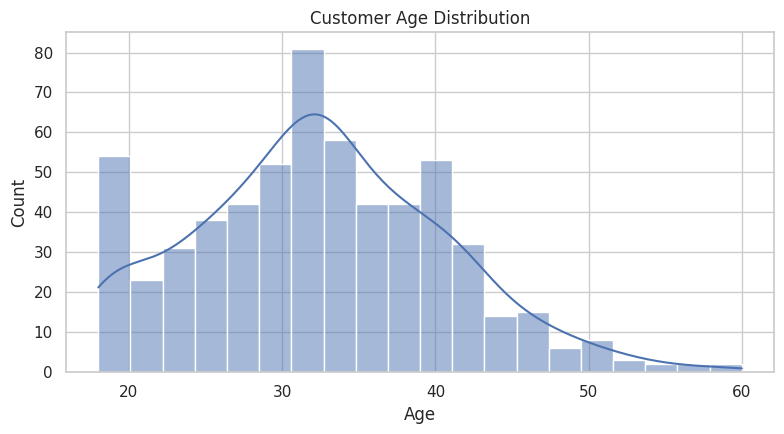

In [16]:
plt.figure(figsize=(8,4.5))
sns.histplot(df["customer_age"], bins=20, kde=True)
plt.title("Customer Age Distribution"); plt.xlabel("Age")
save("03_hist_age")

### 6.4 Scatter plot – discount vs rating

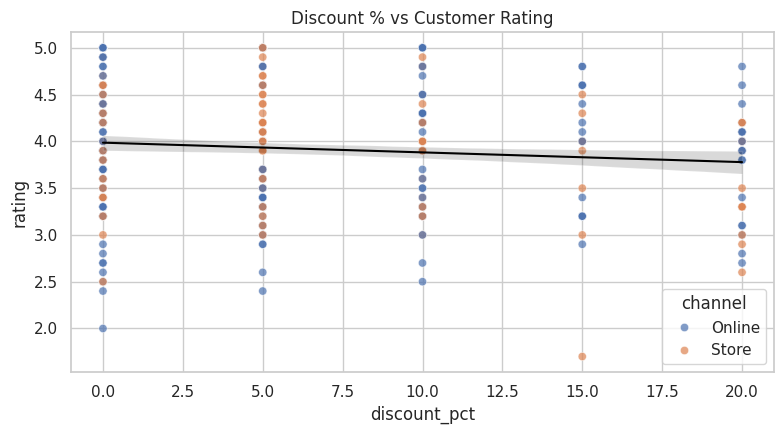

In [17]:
plt.figure(figsize=(8,4.5))
sns.scatterplot(data=df.sample(300, random_state=1), x="discount_pct", y="rating", hue="channel", alpha=0.7)
sns.regplot(data=df, x="discount_pct", y="rating", scatter=False, color="black", line_kws={"linewidth":1.5})
plt.title("Discount % vs Customer Rating")
save("04_scatter_discount_rating")

### 6.5 Box plot – revenue by product

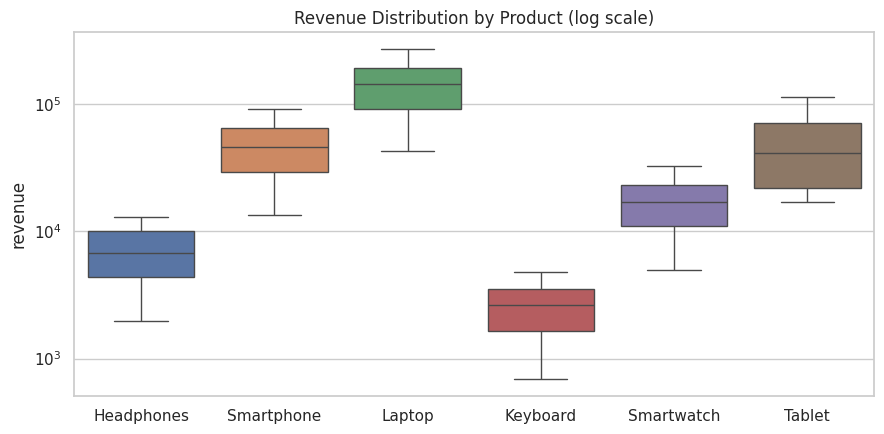

In [18]:
plt.figure(figsize=(9,4.5))
sns.boxplot(data=df, x="product", y="revenue", hue="product", legend=False)
plt.yscale("log"); plt.title("Revenue Distribution by Product (log scale)"); plt.xlabel("")
save("05_box_revenue_product")

### 6.6 Heatmap – correlation matrix

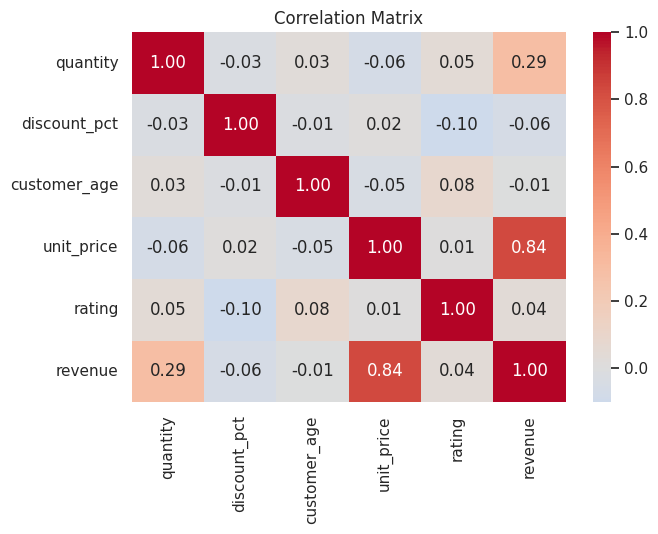

In [19]:
num = df[["quantity", "discount_pct", "customer_age", "unit_price", "rating", "revenue"]]
plt.figure(figsize=(7,5.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
save("06_heatmap_correlation")

### 6.7 Count / categorical comparison – channel by city

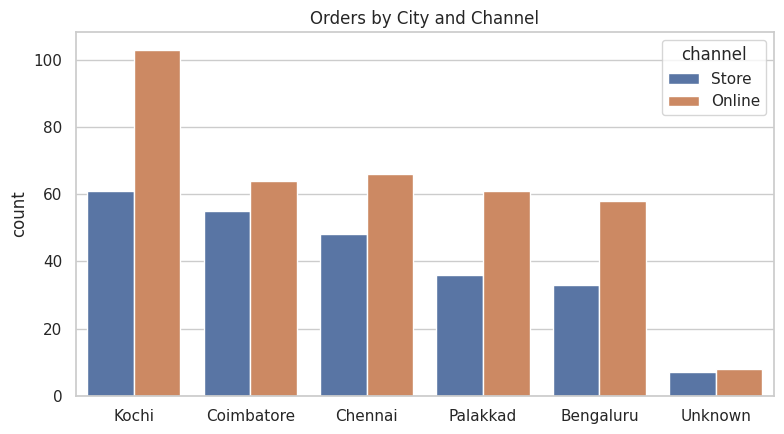

In [20]:
plt.figure(figsize=(8,4.5))
sns.countplot(data=df, x="city", hue="channel", order=df["city"].value_counts().index)
plt.title("Orders by City and Channel"); plt.xlabel("")
save("07_count_city_channel")

## 7. Basic Data Analysis

In [21]:
df[["quantity", "discount_pct", "customer_age", "unit_price", "rating", "revenue"]].describe().round(2)

,quantity,discount_pct,customer_age,unit_price,rating,revenue
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,2.89,6.85,32.43,12878.65,3.91,33389.57
std,1.39,6.51,8.22,15331.63,0.66,47573.61
min,1.00,0.00,18.00,795.00,1.60,688.00
25%,2.00,0.00,27.00,2358.50,3.50,4134.88
50%,3.00,5.00,32.00,5985.00,4.00,15043.12
75%,4.00,10.00,38.00,18373.00,4.40,45574.70
max,5.00,20.00,60.00,61157.00,5.00,270815.00


In [22]:
print("Skewness:\n", num.skew().round(2))
print("\nRevenue share by channel:\n", (df.groupby("channel")["revenue"].sum() / df["revenue"].sum()).round(3))
print("\nAverage rating by discount band:")
print(df.groupby(pd.cut(df["discount_pct"], [-1, 0, 10, 20], labels=["No discount", "5-10%", "15-20%"]), observed=True)["rating"].mean().round(2))

Skewness:
 quantity        0.12
discount_pct    0.65
customer_age    0.30
unit_price      1.69
rating         -0.33
revenue         2.61
dtype: float64

Revenue share by channel:
 channel
Online    0.591
Store     0.409
Name: revenue, dtype: float64

Average rating by discount band:
discount_pct
No discount    3.96
5-10%          3.96
15-20%         3.75
Name: rating, dtype: float64


In [23]:
# does discount really relate to rating?  (Pearson r + simple regression slope with NumPy)
r = df["discount_pct"].corr(df["rating"])
slope, intercept = np.polyfit(df["discount_pct"], df["rating"], 1)
print(f"Pearson r = {r:.3f}; each +1% discount changes rating by {slope:.4f}")

Pearson r = -0.102; each +1% discount changes rating by -0.0104


## 8. Observations & Insights

In [24]:
top = by_product.index[0]
share = by_product["revenue"].iloc[0] / by_product["revenue"].sum()
best_month = monthly.idxmax()
online_share = df.groupby("channel")["revenue"].sum()["Online"] / df["revenue"].sum()
best_city = df.groupby("city")["revenue"].sum().drop("Unknown", errors="ignore").idxmax()
print(f"1. {top} generates {share:.0%} of revenue despite not being the most frequently ordered product.")
print(f"2. Revenue peaked in {best_month}; the monthly trend fluctuates without a strong seasonal pattern.")
print(f"3. Online channel contributes {online_share:.0%} of revenue.")
print(f"4. {best_city} is the highest-revenue city.")
print(f"5. Discount and rating show a weak negative correlation (r = {r:.2f}); discounts do not boost satisfaction.")
print(f"6. Revenue is strongly right-skewed (skew = {num['revenue'].skew():.1f}) because of high-ticket items, so median is a better 'typical order' measure than mean.")

1. Laptop generates 40% of revenue despite not being the most frequently ordered product.
2. Revenue peaked in 2025-10; the monthly trend fluctuates without a strong seasonal pattern.
3. Online channel contributes 59% of revenue.
4. Kochi is the highest-revenue city.
5. Discount and rating show a weak negative correlation (r = -0.10); discounts do not boost satisfaction.
6. Revenue is strongly right-skewed (skew = 2.6) because of high-ticket items, so median is a better 'typical order' measure than mean.


## 9. Conclusion
The notebook walked through a complete, reproducible workflow: environment setup → data loading → Pandas/NumPy manipulation → cleaning (duplicates, missing values, inconsistent text, wrong types, impossible values) → seven visualizations → descriptive and correlation analysis → business insights. All outputs are re-creatable by running **Kernel → Restart & Run All**.